# Aprendizaje Automático
#### Segundo cuatrimestre 2026

## Aprendizaje no supervisado

Una muy breve introducción.

#### Bibliografía: 
* The Elements of Statistical Learning, Trevor Hastie, Robert Tibshirani, Jerome Friedman. Capítulo 14 (y 8.5).
* Pattern Recognition and Machine Learning, Christopher M. Bishop. Capítulo 9.

Para una introducción más liviana, ver:
* An Introduction to Statistical Learning (with Applications in R), Gareth James, Daniela Witten, Trevor Hastie, Robert Tibshirani. Capítulo 10.

e infinitos lugares más...

### Aprendizaje no supervisado

"El objetivo del aprendizaje no supervisado es encontrar estructura en los datos sin etiquetas."

No sirve esta definición en los términos en los cuáles solemos pensar el aprendizaje automático en esta materia.

#### Aprendizaje supervisado

$(X,Y)$ son variables aleatorias. Su distribución conjunta $P(X,Y)$ es una descripción completa del fenómeno que queremos modelar, aunque muchas veces nos alcanza con modelar la distribución condicional $P(Y|X)$.

Incluso, no nos interesa la distribución completa, sino sólo alguna característica de la misma, en general algunos parámetros $\mu$ asociados a la distribución condicional, como por ejemplo los coeficientes de una regresión lineal. En general,

$$\mu(x) = \argmin_\theta \; E_{Y|X}\big[L(Y, \theta)\big]$$

donde $L(\cdot, \cdot)$ es una función de pérdida adecuada.

### Aprendizaje no supervisado

#### Aprendizaje supervisado

En el aprendizaje supervisado, en general $P(X)$ no nos interesa. Sólo nos interesa $P(Y|X)$, o alguna característica de la misma.

**Otra forma de verlo**

*Learning with a teacher*: el "estudiante" presenta $\hat{y_i}$ para cada $x_i$, y el "profesor" le dice cuál es la verdadera $y_i$ y/o el error que cometió, $L(y_i, \hat{y_i})$. El estudiante usa esta información para mejorar su desempeño.

### Aprendizaje no supervisado

Queremos obtener información sobre $P(X)$ a partir de muestras $\{x_i\}_{i=1}^N$.

¿Cuáles son las dificultades?
* No hay una "verdad" objetiva contra la cuál comparar. Es decir, es "learning without a teacher".
* La dimensión de $X$ puede ser muy alta.
* Nos interesan características complejas de $P(X)$, como su estructura multimodal, correlaciones entre variables, etc. Es decir, no solo centroides y varianzas.

¿Alguna ventaja? Si $X$ representa todo lo que queremos modelar, no es necesario modelar $P(X)$ condicionalmente a otra variable.

### Aprendizaje no supervisado

El aprendizaje no supervisado incorpora dos grandes herramientas para abordar este problema:

* Reducción de dimensionalidad
* Clustering

#### Reducción de dimensionalidad

* Busca encontrar estructuras (*manifolds*) de baja dimensión en el espacio de $X$ que representen regiones de alta densidad de probabilidad.
* Provee información sobre la relación entre las variables originales y si existe una representación más compacta de las mismas (variables *latentes*).


### Aprendizaje no supervisado

El aprendizaje no supervisado incorpora dos grandes herramientas para abordar este problema:

* Reducción de dimensionalidad
* Clustering

#### Clustering

* ~~Busca agrupar las muestras en grupos (*clusters*) de acuerdo a alguna métrica de similitud~~.
* Busca regiones de alta densidad de probabilidad en el espacio de $X$ (modas de $P(X)$), separadas por regiones de baja densidad.

In [31]:
import numpy as np
import matplotlib.pyplot as plt

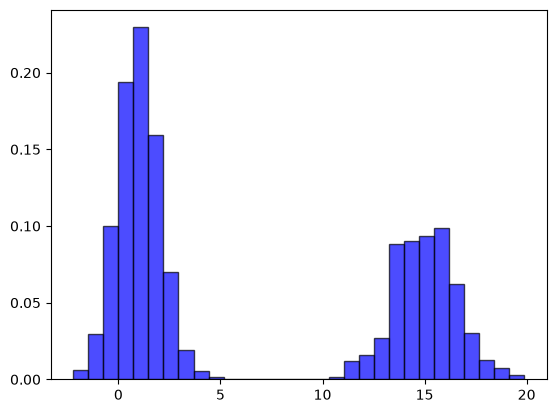

In [41]:
np.random.seed(100)
n_1 = 1200
n_2 = 800

mu_1 = 1
mu_2 = 15
sigma_1 = 1
sigma_2 = 1.5

samples_1 = np.random.normal(loc=mu_1, scale=sigma_1, size=n_1)
samples_2 = np.random.normal(loc=mu_2, scale=sigma_2, size=n_2)

samples = np.concatenate([samples_1, samples_2])
samples = samples[np.random.permutation(len(samples))]

plt.hist(samples, bins=30, alpha=0.7, color='blue', edgecolor='black', density=True)
plt.show()

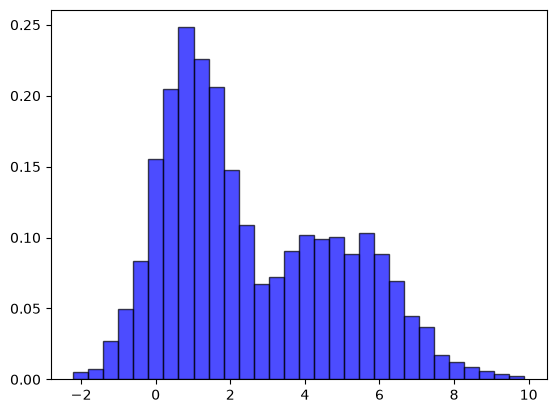

### Clustering

**Un ejemplo sencillo**

Vamos a modelar las observaciones como provenientes de una mezcla (mixtura) de distribuciones gaussianas.

$$ \begin{aligned}
    Y_1 \sim \mathcal{N}(\mu_1, \sigma_1^2) \\
    Y_2 \sim \mathcal{N}(\mu_2, \sigma_2^2) \\
    Y = (1 - \Delta) Y_1 + \Delta Y_2
\end{aligned} $$

donde $\Delta$ es una variable aleatoria de Bernoulli con parámetro $\pi$. Es decir, $\Delta \in \{0,1\}$ y 

$$P(\Delta = 0) = 1-\pi \qquad \text{(la fracción de los datos que viene de la población 1) y}$$
$$P(\Delta = 1) = \pi \qquad \text{(la fracción de los datos que viene de la población 2).}$$

Por la regla del producto, la conjunta de $(y_i, \Delta_i)$ es

$$p(y_i,\Delta_i) = P(\Delta_i)\,p(y_i\mid\Delta_i)$$

y para cada variable aleatoria condicionada 

$$y_i \mid \Delta_i = 0 \sim \mathcal{N}(\mu_1, \sigma_1^2), \qquad y_i \mid \Delta_i = 1 \sim \mathcal{N}(\mu_2, \sigma_2^2)$$



Llamando $\phi_{\theta}$ a la densidad normal de parámetros $\theta=(\mu,\sigma^2)$, tenemos $P(\Delta_i=1)=\pi$, $P(\Delta_i=0)=1-\pi$, y 

$$p(y_i,\Delta_i=0) = (1-\pi)\,\phi_{\theta_1}(y_i), \qquad p(y_i,\Delta_i=1) = \pi\,\phi_{\theta_2}(y_i)$$

Marginalizando sobre $\Delta_i$, la densidad de $Y$ es

$$g_Y(y) = (1-\pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y)$$

¿Cómo podemos estimar los parámetros $\theta_1 = (\mu_1, \sigma_1^2)$, $\theta_2 = (\mu_2, \sigma_2^2)$ y $\pi$ a partir de una muestra $y_1, \ldots, y_n$?

La función de distribución de $Y$ es

$$P(Y \le y) = P(Y \le y \mid \Delta = 0)\,P(\Delta = 0) + P(Y \le y \mid \Delta = 1)\,P(\Delta = 1)$$

que condicionando a $\Delta = 0$, se tiene $Y = Y_1$, y condicionado a $\Delta = 1$, se tiene $Y = Y_2$

$$P(Y \le y) = (1-\pi)\,P(Y_1 \le y) + \pi\,P(Y_2 \le y)$$

$P(Y_1 \le y)$ es la función de distribución acumulada (CDF) de $Y_1$. Como $Y_1 \sim \mathcal{N}(\mu_1, \sigma_1^2)$, es

$$P(Y_1 \le y) = \int_{-\infty}^{y} \phi_{\theta_1}(t)\, dt$$

donde $\phi_{\theta_1}$ es la densidad.

### Clustering

**Un ejemplo sencillo**

$$ g_Y(y) = (1 - \pi) \phi_{\theta_1}(y) + \pi \phi_{\theta_2}(y) $$

¿Cómo podemos estimar los parámetros $(\mu_1, \sigma_1^2, \mu_2, \sigma_2^2, \pi)$?

¡Máxima verosimilitud!

$$ \mathcal{l}(\theta; \textbf{Z}) = \sum_{i=1}^N \log [(1 - \pi) \phi_{\theta_1}(y_i) + \pi \phi_{\theta_2}(y_i)]$$

donde $\textbf{Z} = (y_1, \ldots, y_N)$.

Es difícil maximizar esta función directamente, ya que hay términos de suma dentro del logaritmo. Pero podemos suponer que hay variables latentes **no-observadas** $\Delta_1, \ldots, \Delta_N$ asociadas a cada observación, que indican de qué componente de la mezcla proviene cada observación. Es decir, $\Delta_i = 0$ si $y_i$ proviene de la primera gaussiana, o $\Delta_i = 1$ si proviene de la segunda gaussiana.

### Clustering

**Un ejemplo sencillo**

$$ g_Y(y) = (1 - \pi) \phi_{\theta_1}(y) + \pi \phi_{\theta_2}(y) $$

$$ \mathcal{l}(\theta; \textbf{Z}) = \sum_{i=1}^N \log [(1 - \pi) \phi_{\theta_1}(y_i) + \pi \phi_{\theta_2}(y_i)]$$

Si incorporamos las variables latentes $\Delta_i$, la función de verosimilitud queda:

$$ \mathcal{l}(\theta; \textbf{Z}, \boldsymbol{\Delta}) = \sum_{i=1}^N [ (1 - \Delta_i) \log [(1 - \pi) \phi_{\theta_1}(y_i)] + \Delta_i \log [\pi \phi_{\theta_2}(y_i)]] $$

$$ \mathcal{l}(\theta; \textbf{Z}, \boldsymbol{\Delta}) = \sum_{i=1}^N [ (1 - \Delta_i) \log \phi_{\theta_1}(y_i) + \Delta_i \log \phi_{\theta_2}(y_i)] + \sum_{i=1}^N [ (1 - \Delta_i) \log (1 - \pi) + \Delta_i \log \pi ] $$

También lo puedo pensar como que 

$$p(y_i, 0) = (1-\pi)\,\phi_{\theta_1}(y_i)$$
$$p(y_i, 1) = \pi\,\phi_{\theta_2}(y_i)$$

se pueden resumir en

$$p(y_i, \Delta_i) = \big[(1-\pi)\,\phi_{\theta_1}(y_i)\big]^{1-\Delta_i}\,\big[\pi\,\phi_{\theta_2}(y_i)\big]^{\Delta_i}$$

Si los pares $(y_i, \Delta_i)$, $i = 1,\dots,N$, son independientes, la verosimilitud es el producto:

$$L(\theta; \mathbf{Z}, \boldsymbol{\Delta}) = \prod_{i=1}^N \big[(1-\pi)\,\phi_{\theta_1}(y_i)\big]^{1-\Delta_i}\,\big[\pi\,\phi_{\theta_2}(y_i)\big]^{\Delta_i}$$

donde tomando logaritmo, el log convierte el producto en suma y los exponentes en factores multiplicativos.

### Clustering

**Un ejemplo sencillo**

$$ \mathcal{l}(\theta; \textbf{Z}, \boldsymbol{\Delta}) = \sum_{i=1}^N [ (1 - \Delta_i) \log \phi_{\theta_1}(y_i) + \Delta_i \log \phi_{\theta_2}(y_i)] + \sum_{i=1}^N [ (1 - \Delta_i) \log (1 - \pi) + \Delta_i \log \pi ] $$

De esta forma, las estimaciones de $u_1, \sigma_1^2$ son el promedio y varianza empírica de las observaciones con $\Delta_i = 0$, y las de $u_2, \sigma_2^2$ son el promedio y varianza empírica de las observaciones con $\Delta_i = 1$. La estimación de $\pi$ es la proporción de observaciones con $\Delta_i = 1$.

$$\hat\mu_1 = \frac{\sum_i (1-\Delta_i)\,y_i}{\sum_i (1-\Delta_i)}, \qquad \hat\mu_2 = \frac{\sum_i \Delta_i\, y_i}{\sum_i \Delta_i}, \qquad \hat\pi = \frac{\sum_i \Delta_i}{N}.$$

Pero no conocemos las $\Delta_i$...

### Clustering

**Un ejemplo sencillo**

La forma de resolver este problema es el algoritmo EM (Expectation-Maximization), un algoritmo iterativo que alterna entre:

* Estimación de las variables latentes $\Delta_i$ a partir de los parámetros actuales (E-step)
* Maximización de la función de verosimilitud completa con respecto a los parámetros, asumiendo las $\Delta_i$ estimadas (M-step)

Veamos en detalle cómo funciona.

### Clustering

**Un ejemplo sencillo**

El paso de estimación de las variables latentes (E-step) lo podemos entender como una asignación "suave" de cada observación a cada componente de la mezcla. Para ello, necesitamos calcular su esperanza condicional.

$$ \gamma_i (\theta) = E[\Delta_i | \theta, \textbf{Z}] = P(\Delta_i = 1 | \theta,\textbf{Z}) $$

A estas magnitudes se las llama *responsabilidades* (con respecto al modelo 2). Para este caso, 
$$ \gamma_i (\theta) = \frac{\pi \phi_{\theta_2}(y_i)}{(1 - \pi) \phi_{\theta_1}(y_i) + \pi \phi_{\theta_2}(y_i)} $$

que es un estimador de $\Delta_i$, salvo que $\gamma_i (\theta) \in{[0,1]}$.

Pero no conocemos los parámetros $\theta$...

### Clustering

**Un ejemplo sencillo**

#### Algorithm EM para una mezcla de gaussianas de dos componentes

1. Inicializar los parámetros $\hat{\mu_1}, \hat{\sigma_1^2}, \hat{\mu_2}, \hat{\sigma_2^2}, \hat{\pi}$
2. **E-step** - Calcular las responsabilidades
   $$ \hat{\gamma_i} = \frac{\hat{\pi} \phi_{\hat{\theta_2}}(y_i)}{(1 - \hat{\pi}) \phi_{\hat{\theta_1}}(y_i) + \hat{\pi} \phi_{\hat{\theta_2}}(y_i)} $$
   para $i = 1, \ldots, N$

### Clustering

**Un ejemplo sencillo**

#### Algorithm EM para una mezcla de gaussianas de dos componentes

3. **M-step** - Actualizar los parámetros usando las responsabilidades:
    $$ \hat{\mu_1} = \frac{\sum_{i=1}^N (1 - \hat{\gamma_i}) y_i}{\sum_{i=1}^N (1 - \hat{\gamma_i})}\qquad \hat{\sigma_1}^2 = \frac{\sum_{i=1}^N (1 - \hat{\gamma_i}) (y_i - \hat{\mu_1})^2}{\sum_{i=1}^N (1 - \hat{\gamma_i})} $$

    $$ \hat{\mu_2} = \frac{\sum_{i=1}^N \hat{\gamma_i} y_i}{\sum_{i=1}^N \hat{\gamma_i}} \qquad 
    \hat{\sigma_2}^2 = \frac{\sum_{i=1}^N \hat{\gamma_i} (y_i - \hat{\mu_2})^2}{\sum_{i=1}^N \hat{\gamma_i}} $$
    $$ \hat{\pi} = \frac{1}{N} \sum_{i=1}^N \hat{\gamma_i} $$
4. Repetir pasos 2 y 3 hasta convergencia.

In [42]:
from scipy.stats import norm

# Buena forma de inicializar (ESL, p. 274)
mu_1_0 = np.random.choice(samples, size=1)[0]
mu_2_0 = np.random.choice(samples, size=1)[0]
sigma_1_0 = np.std(samples)
sigma_2_0 = np.std(samples)
pi_0 = 0.5

all_mu_1 = [mu_1_0]
all_mu_2 = [mu_2_0]
all_sigma_1 = [sigma_1_0]
all_sigma_2 = [sigma_2_0]
all_pi = [pi_0]


pdfs_1 = norm.pdf(samples, loc=all_mu_1[0], scale=all_sigma_1[0])
pdfs_2 = norm.pdf(samples, loc=all_mu_2[0], scale=all_sigma_2[0])
    
l_0 = np.sum(np.log(pi_0 * pdfs_2 + (1 - pi_0) * pdfs_1)) 
all_l = [l_0]

n_iterations = 20

for i in range(n_iterations):
    pdfs_1 = norm.pdf(samples, loc=all_mu_1[i], scale=all_sigma_1[i])
    pdfs_2 = norm.pdf(samples, loc=all_mu_2[i], scale=all_sigma_2[i])

    responsabilities = all_pi[i] * pdfs_2 / (all_pi[i] * pdfs_2 + (1 - all_pi[i]) * pdfs_1)

    mu_1_i = np.sum((1 - responsabilities) * samples) / np.sum(1 - responsabilities)
    mu_2_i = np.sum(responsabilities * samples) / np.sum(responsabilities)

    sigma_1_i = np.sqrt(np.sum((1 - responsabilities) * (samples - mu_1_i) ** 2) / np.sum(1 - responsabilities))
    sigma_2_i = np.sqrt(np.sum(responsabilities * (samples - mu_2_i) ** 2) / np.sum(responsabilities))

    pi_i = np.sum(responsabilities) / len(samples)

    pdfs_1 = norm.pdf(samples, loc=mu_1_i, scale=sigma_1_i)
    pdfs_2 = norm.pdf(samples, loc=mu_2_i, scale=sigma_2_i)
    l_i = np.sum(np.log(pi_i * pdfs_2 + (1 - pi_i) * pdfs_1))
    all_l.append(l_i)

    all_mu_1.append(mu_1_i)
    all_mu_2.append(mu_2_i)
    all_sigma_1.append(sigma_1_i)
    all_sigma_2.append(sigma_2_i)
    all_pi.append(pi_i)

In [34]:
print(all_mu_1)

[np.float64(3.7087489218692355), np.float64(1.9528298861691993), np.float64(1.8579891593209108), np.float64(1.7484811171128316), np.float64(1.6290544856117821), np.float64(1.5137982474685803), np.float64(1.417898679592388), np.float64(1.3429840202173022), np.float64(1.2818737021883697), np.float64(1.229428407476022), np.float64(1.1836291920862252), np.float64(1.1438098140205422), np.float64(1.109622382580529), np.float64(1.0806639169720127), np.float64(1.056402901562927), np.float64(1.0362220453648883), np.float64(1.0194888978705028), np.float64(1.0056131036953004), np.float64(0.9940781322780656), np.float64(0.9844509395466758), np.float64(0.976377896674409)]


Text(0.5, 1.0, 'Log-Likelihood')

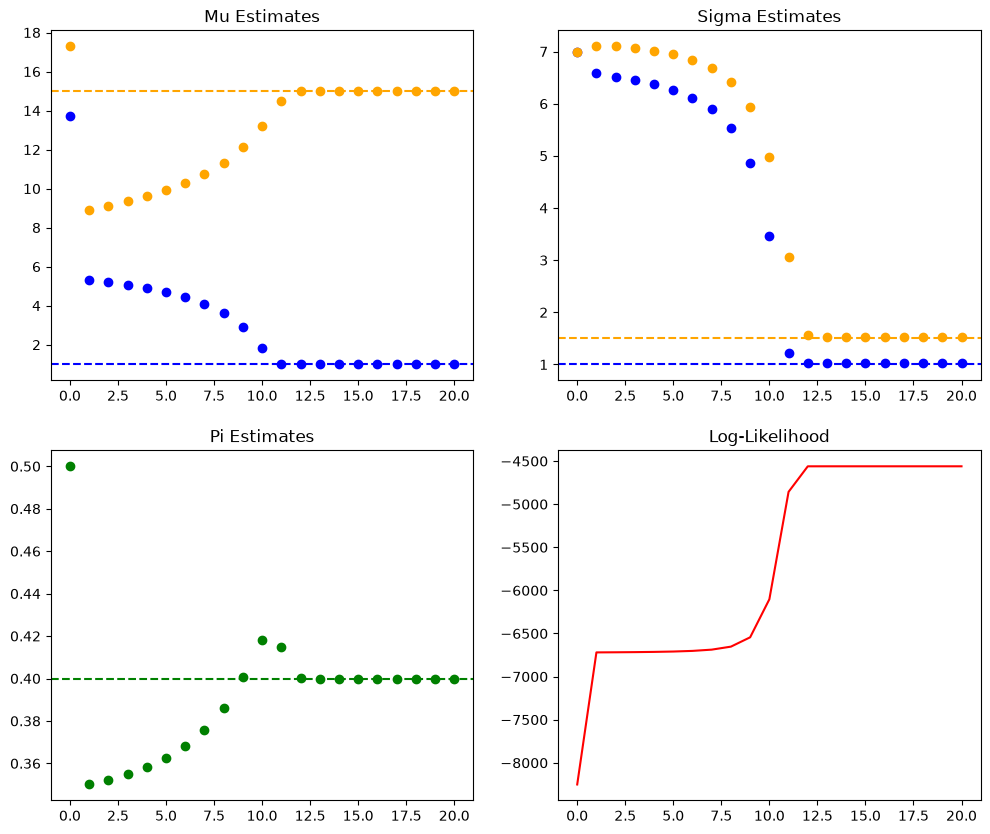

In [43]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
axs = axs.ravel()

axs[0].scatter(range(len(all_mu_1)), all_mu_1, label='mu 1', color='blue')
axs[0].axhline(mu_1, color='blue', linestyle='--')
axs[0].set_title('Mu Estimates')

axs[0].scatter(range(len(all_mu_2)), all_mu_2, label='mu 2', color='orange')
axs[0].axhline(mu_2, color='orange', linestyle='--')

axs[1].scatter(range(len(all_sigma_1)), all_sigma_1, label='sigma 1', color='blue')
axs[1].axhline(sigma_1, color='blue', linestyle='--')
axs[1].set_title('Sigma Estimates')

axs[1].scatter(range(len(all_sigma_2)), all_sigma_2, label='sigma 2', color='orange')
axs[1].axhline(sigma_2, color='orange', linestyle='--')

axs[2].scatter(range(len(all_pi)), all_pi, label='pi', color='green')
axs[2].axhline(n_2 / (n_1 + n_2), color='green', linestyle='--')
axs[2].set_title('Pi Estimates')

axs[3].plot(range(len(all_l)), all_l, label='log-likelihood', color='red')
axs[3].set_title('Log-Likelihood')

In [47]:
import plotly.graph_objects as go

def resp_at(it):
    p1 = norm.pdf(samples, all_mu_1[it], all_sigma_1[it])
    p2 = norm.pdf(samples, all_mu_2[it], all_sigma_2[it])
    pi = all_pi[it]
    return pi * p2 / (pi * p2 + (1 - pi) * p1)

def boundary_line(it):
    b = samples[np.argmin(np.abs(resp_at(it) - 0.5))]
    return go.Scatter(x=[b, b], y=[0, 1], mode='lines', name='boundary it n° ' + str(it), line=dict(dash='dot'))

n_it = len(all_pi)
r0 = resp_at(0)

fig = go.Figure(
    data=[
        go.Scatter(x=samples, y=1-r0, mode='markers', name='responsabilities',
                   marker=dict(color='purple', opacity=0.5)),
        go.Scatter(x=samples, y=r0, mode='markers', name='1 - responsabilities',
                   marker=dict(color='orange', opacity=0.5)),
        boundary_line(0),
    ],
    frames=[go.Frame(name=str(i),
                     data=[go.Scatter(x=samples, y=resp_at(i)),
                           go.Scatter(x=samples, y=1 - resp_at(i)),
                           boundary_line(i)])
            for i in range(n_it)],
)

fig.update_layout(
    title='Responsabilities por iteración',
    xaxis=dict(title='Sample value', range=[-2, 30]),
    yaxis=dict(title='Responsability', range=[-0.05, 1.05]),
    sliders=[dict(
        active=0,
        currentvalue={'prefix': 'Iteración: '},
        steps=[dict(method='animate', label=str(i),
                    args=[[str(i)], dict(mode='immediate',
                                         frame=dict(duration=0, redraw=True))])
               for i in range(n_it)],
    )],
)

fig.show()

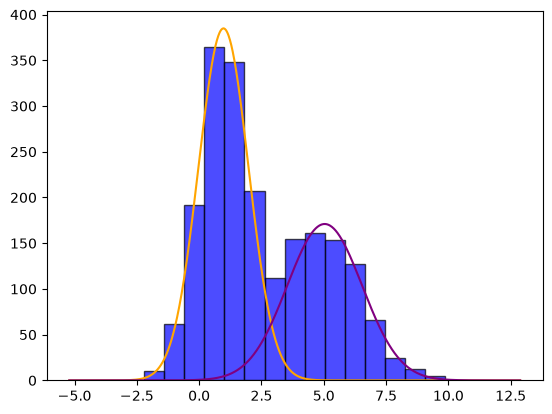

In [37]:
plt.hist(samples, bins=15, alpha=0.7, color='blue', edgecolor='black')

x = np.linspace(min(samples) - 3, max(samples) + 3, 1000)
final_mu_1 = all_mu_1[-1]
final_mu_2 = all_mu_2[-1]
final_sigma_1 = all_sigma_1[-1]
final_sigma_2 = all_sigma_2[-1]
final_pi = all_pi[-1]

pdf_1 = norm.pdf(x, loc=final_mu_1, scale=final_sigma_1)
pdf_2 = norm.pdf(x, loc=final_mu_2, scale=final_sigma_2)
plt.plot(x, (1 - final_pi) * pdf_1 * len(samples) * (max(samples) - min(samples)) / 15, color='orange', label='Component 1')
plt.plot(x, final_pi * pdf_2 * len(samples) * (max(samples) - min(samples)) / 15, color='purple', label='Component 2')
plt.show()

### Clustering

**Caso K gaussianas**

Con K gaussianas, la densidad pasa a ser

$$p(x) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(x \mid \mu_k, \sigma_k^2), \qquad \pi_k \ge 0,\quad \sum_{k=1}^K \pi_k = 1$$

donde ahora hay K pesos con la restricción de que sumen 1 (o sea, K−1 parámetros libres).

Conviene introducir una variable latente $z \in \{1,\dots,K\}$ codificada como vector one-hot, con 

$$p(z=k)=\pi_k, \qquad p(x \mid z=k)=\mathcal{N}(x\mid\mu_k,\sigma_k^2)$$

### Clustering

**Caso K gaussianas**

Con 2 gaussianas la responsabilidad de una componente es un cociente y la otra es su complemento. Con K, la idea es la misma pero normalizando sobre todas las componentes:

$$\gamma_{ik} = p(z_i=k \mid x_i) = \frac{\pi_k \, \mathcal{N}(x_i \mid \mu_k, \sigma_k^2)}{\sum_{j=1}^{K} \pi_j \, \mathcal{N}(x_i \mid \mu_j, \sigma_j^2)}$$

### Clustering

**Caso multivariado**

Para $x \in \mathbb{R}^D$, cada componente es una gaussiana multivariada con media $\mu_k \in \mathbb{R}^D$ y covarianza $\Sigma_k \in \mathbb{R}^{D\times D}$:

$$\mathcal{N}(x\mid\mu_k,\Sigma_k) = \frac{1}{(2\pi)^{D/2}|\Sigma_k|^{1/2}} \exp\!\left(-\tfrac12 (x-\mu_k)^\top \Sigma_k^{-1}(x-\mu_k)\right)$$

y así...

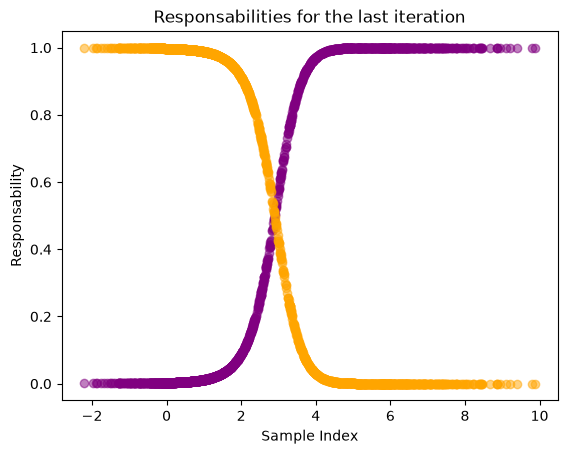

In [38]:
# Plot responsabilities for the last iteration
pdfs_1 = norm.pdf(samples, loc=all_mu_1[-1], scale=all_sigma_1[-1])
pdfs_2 = norm.pdf(samples, loc=all_mu_2[-1], scale=all_sigma_2[-1])
responsabilities = all_pi[-1] * pdfs_2 / (all_pi[-1] * pdfs_2 + (1 - all_pi[-1]) * pdfs_1)

plt.scatter(samples, responsabilities, label='responsabilities', color='purple', alpha=0.5)
plt.scatter(samples, 1 - responsabilities, label='1 - responsabilities', color='orange', alpha=0.5)

plt.title('Responsabilities for the last iteration')
plt.xlabel('Sample Index')
plt.ylabel('Responsability')
plt.show()